# Воспроизведение эксперимента

Источник: [Amazon Reviews 2023, Software](https://amazon-reviews-2023.github.io/).
Рекомендуются ранее не встречавшиеся пользователю товары (`parent_asin`). Одно взаимодействие — отзыв с оценкой, а не обязательно подтверждённая покупка. `timestamp` задан в миллисекундах Unix; релевантность в validation/test: `rating >= 4`.

Запускайте notebook из каталога `hw1/` репозитория (ветка `master`) в окружении с установленным `requirements.txt` (команды — в README). Ячейки идут последовательно: скачивание reviews и metadata → конвертация → дедупликация и 5-core → temporal split → сохранение train/val/test/items_train → создание исходных артефактов CPU/FM и validation-таблиц → tuning → финальный test.

Блок **«Создание исходных артефактов»** ниже запускает обучение и validation только при отсутствии нужных файлов. Само добавление этого блока не означает его выполнение: текущие outputs оставлены от ранее проведённых экспериментов. FM обучается с seed=42, dim=32, lr=0.003, weight_decay=0.0001, 15 эпохами и checkpoint каждые 3 эпохи. Для CPU используются параметры, явно указанные в коде ниже. Большие файлы хранятся локально в data/ и artifacts/, в Git их нет. Для нового датасета/сплита используйте чистый отдельный checkout: наличие кеша не подтверждает совпадение его содержимого с новой подготовкой.

Основная метрика выбора параметров — NDCG@10; Recall@10 дополняет оценку полноты. Test применяется после выбора настроек. Сохранённые outputs могут отличаться от будущего прогона из-за окружения и выбора при равных score; побитовая воспроизводимость не заявляется.

Описание датасета и ФИО: [DATA.md](DATA.md). Общий README с ФИО находится на уровень выше.


In [14]:
import polars as pl
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from utils.data import *

In [15]:
REVIEWS_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Software.jsonl.gz"

raw_path = Path("data/raw/Software.jsonl.gz")
parquet_path = Path("data/processed/reviews.parquet")

In [4]:
download_file(REVIEWS_URL, raw_path)

Software.jsonl.gz: 100%|██████████| 496M/496M [09:11<00:00, 899kB/s]  


PosixPath('data/raw/Software.jsonl.gz')

In [16]:
parquet_path.parent.mkdir(parents=True, exist_ok=True)

if parquet_path.exists():
    print(f"Parquet already exists: {parquet_path}")
else:
    reviews_to_parquet(raw_path, parquet_path)

Parquet already exists: data/processed/reviews.parquet


In [17]:
reviews = pl.read_parquet(parquet_path)

In [18]:
reviews.head()

user_id,item_id,rating,timestamp,verified_purchase
str,str,f32,i64,bool
"""AGCI7FAH4GL5FI65HYLKWTMFZ2CQ""","""B0BQSK9QCF""",1.0,1562182632076,false
"""AHSPLDNW5OOUK2PLH7GXLACFBZNQ""","""B00CTQ6SIG""",5.0,1424120336000,true
"""AHSPLDNW5OOUK2PLH7GXLACFBZNQ""","""B0066WJLU6""",5.0,1362399267000,true
"""AH6CATODIVPVUOJEWHRSRCSKAOHA""","""B00KCYMAWK""",4.0,1561061428662,true
"""AEINY4XOINMMJCK5GZ3M6MMHBN6A""","""B00P1RK566""",4.0,1418257196000,true


In [19]:
reviews.schema, reviews.shape

(Schema([('user_id', String),
         ('item_id', String),
         ('rating', Float32),
         ('timestamp', Int64),
         ('verified_purchase', Boolean)]),
 (4880181, 5))

# Что по уникальным ?

In [20]:
print("Interactions: ", reviews.height)
print("Users:", reviews["user_id"].n_unique())
print("Items:", reviews["item_id"].n_unique())

Interactions:  4880181
Users: 2589466
Items: 89246


# Считаем уникальность каждого рейтинги

In [21]:
reviews["rating"].value_counts().sort("rating")

rating,count
f32,u32
1.0,695854
2.0,239253
3.0,419356
4.0,857082
5.0,2668636


# Считаем полные пропуски 

In [22]:
reviews.null_count()

user_id,item_id,rating,timestamp,verified_purchase
u32,u32,u32,u32,u32
0,0,0,0,0


# Считаем диапазон времен

In [23]:
# конвертируем дату

reviews = reviews.with_columns(
    pl.from_epoch("timestamp", time_unit="ms").alias("datetime")
)

In [24]:
reviews.select(
    pl.col("timestamp").min().alias("min_timestamp"),
    pl.col("timestamp").max().alias("max_timestamp"),
)

min_timestamp,max_timestamp
i64,i64
921470559000,1694398391515


In [25]:
reviews.select(
    pl.col("datetime").min().alias("min_datetime"),
    pl.col("datetime").max().alias("max_datetime"),
)

min_datetime,max_datetime
datetime[μs],datetime[μs]
1999-03-15 04:02:39,2023-09-11 02:13:11.515


# Считаем активность каждого user с items

In [26]:
user_activity = (reviews.group_by("user_id").len().sort("len"))

# Считаем активность item с users


In [27]:
item_popularity = (reviews.group_by("item_id").len().sort("len"))

# Посмотрим на распредление

In [28]:
user_activity.describe()
item_popularity.describe()

statistic,item_id,len
str,str,f64
"""count""","""89246""",89246.0
"""null_count""","""0""",0.0
"""mean""",null,54.68235
"""std""",null,598.835582
"""min""","""0005162092""",1.0
"""25%""",null,1.0
"""50%""",null,3.0
"""75%""",null,10.0
"""max""","""b017poz7y2""",50891.0


##
* Видно что распределение перекошено и 50% процентов имеет не блее 3 interactions, 25% = 1, 75% items имеют не более 10 interactions. Хотя среднее значение 54.7

##  Посмотрим на дубликаты (user_id, item_id)

In [29]:
duplicates = (
    reviews
    .group_by(["user_id", "item_id"])
    .len()
    .filter(pl.col("len") > 1)
)

print("Duplicate user-item pairs:", duplicates.height)

duplicates.head()

Duplicate user-item pairs: 44279


user_id,item_id,len
str,str,u32
"""AE2CVJC7OHUJK3RKGCCBUUQOJQ4A""","""B07GY13Q68""",2
"""AHCERJFVSETBBMTDRZNQFNGGHV5A""","""B00992CF6W""",2
"""AG7FRSDRAJF2CFUC3TDOAKRWJDQA""","""B0055SWM08""",2
"""AH5HXU7IXUDCCJSQA2J4WHVW27GA""","""B00029J1SG""",2
"""AFKLK3LI7C3CUM7ACVJ64J4T5XNQ""","""B007ZGO7EM""",2


# Оставим последнее взаимодействие по дате

In [30]:
reviews = (
    reviews
    .sort("timestamp")
    .unique(
        subset=["user_id", "item_id"],
        keep="last",
        maintain_order=True,
    )
)

In [31]:
reviews.null_count()

user_id,item_id,rating,timestamp,verified_purchase,datetime
u32,u32,u32,u32,u32,u32
0,0,0,0,0,0


# Пересмотрим статистики

In [32]:
reviews["rating"].value_counts().sort("rating")

rating,count
f32,u32
1.0,688368
2.0,236851
3.0,415258
4.0,847635
5.0,2640368


In [33]:
print("Interactions:", reviews.height)
print("Users:", reviews["user_id"].n_unique())
print("Items:", reviews["item_id"].n_unique())

Interactions: 4828480
Users: 2589466
Items: 89246


In [34]:
user_activity = reviews.group_by("user_id").len()
item_popularity = reviews.group_by("item_id").len()

In [35]:
user_activity["len"].describe(), item_popularity["len"].describe()

(shape: (9, 2)
 ┌────────────┬────────────┐
 │ statistic  ┆ value      │
 │ ---        ┆ ---        │
 │ str        ┆ f64        │
 ╞════════════╪════════════╡
 │ count      ┆ 2.589466e6 │
 │ null_count ┆ 0.0        │
 │ mean       ┆ 1.864662   │
 │ std        ┆ 2.692253   │
 │ min        ┆ 1.0        │
 │ 25%        ┆ 1.0        │
 │ 50%        ┆ 1.0        │
 │ 75%        ┆ 2.0        │
 │ max        ┆ 371.0      │
 └────────────┴────────────┘,
 shape: (9, 2)
 ┌────────────┬────────────┐
 │ statistic  ┆ value      │
 │ ---        ┆ ---        │
 │ str        ┆ f64        │
 ╞════════════╪════════════╡
 │ count      ┆ 89246.0    │
 │ null_count ┆ 0.0        │
 │ mean       ┆ 54.103041  │
 │ std        ┆ 592.477216 │
 │ min        ┆ 1.0        │
 │ 25%        ┆ 1.0        │
 │ 50%        ┆ 3.0        │
 │ 75%        ┆ 10.0       │
 │ max        ┆ 50326.0    │
 └────────────┴────────────┘)

In [36]:
# сколько объектов имеют ровно 1, 2, 3, ... взаимодействий.
user_activity.group_by("len").agg(pl.len().alias("count")).sort("len").head(20)
item_popularity.group_by("len").agg(pl.len().alias("count")).sort("len").head(20)

len,count
u32,u32
1,24807
2,14502
3,8464
4,5509
5,4016
…,…
16,660
17,578
18,567


# Сделаем Iterative 5-core фильтрацию, чтобы выкинуть хвост

In [37]:
def iterative_k_core(df, k=5):
    while True:
        n = df.height
        valid_users = df.group_by("user_id").len().filter(pl.col("len") >= k).select("user_id")
        df = df.join(valid_users, on="user_id", how="semi")
        valid_items = df.group_by("item_id").len().filter(pl.col("len") >= k).select("item_id")
        df = df.join(valid_items, on="item_id", how="semi")
        if df.height == n:
            break
    return df

In [38]:
reviews_5core = iterative_k_core(reviews, k=5)

In [39]:
reviews_5core.height, reviews_5core["user_id"].n_unique(), reviews_5core["item_id"].n_unique()

(1276840, 146396, 17591)

### Итоги фильтрации (Iterative 5-core)

После применения итеративной фильтрации $k$-core ($n_u \ge 5, n_i \ge 5$) итоговый датасет содержит:

- **Взаимодействия ($N$):** 1 276 840
- **Пользователи ($|U|$):** 146 396
- **Объекты ($|I|$):** 17 591


# Дампим датасет

In [40]:
clean_path = Path("data/processed/interactions_5core.parquet")
reviews_5core.write_parquet(clean_path)

In [41]:
# Метаданные из той же категории первоисточника Amazon Reviews 2023.
METADATA_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/meta_categories/meta_Software.jsonl.gz"
metadata_raw_path = Path("data/raw/meta_Software.jsonl.gz")
if not Path("data/processed/items.parquet").exists():
    download_file(METADATA_URL, metadata_raw_path)

# Парсим метаданные 
metadata_raw_path = Path("data/raw/meta_Software.jsonl.gz")
metadata_parquet_path = Path("data/processed/items.parquet")

if metadata_parquet_path.exists():
    print(f"Parquet already exists: {metadata_parquet_path}")
else:
    metadata_to_parquet(metadata_raw_path, metadata_parquet_path)

Parquet already exists: data/processed/items.parquet


In [42]:
items = pl.read_parquet(metadata_parquet_path)
items.shape, items.head()

((89251, 6),
 shape: (5, 6)
 ┌────────────┬────────────────────────┬───────────────┬────────────┬───────────────────────┬───────┐
 │ item_id    ┆ title                  ┆ main_category ┆ categories ┆ store                 ┆ price │
 │ ---        ┆ ---                    ┆ ---           ┆ ---        ┆ ---                   ┆ ---   │
 │ str        ┆ str                    ┆ str           ┆ list[str]  ┆ str                   ┆ f32   │
 ╞════════════╪════════════════════════╪═══════════════╪════════════╪═══════════════════════╪═══════╡
 │ B00VRPSGEO ┆ Accupressure Guide     ┆ Appstore for  ┆ []         ┆ mAppsguru             ┆ 0.0   │
 │            ┆                        ┆ Android       ┆            ┆                       ┆       │
 │ B00NWQXXHQ ┆ Ankylosaurus Fights    ┆ Appstore for  ┆ []         ┆ Oceanhouse Media, Inc ┆ 2.99  │
 │            ┆ Back - Smi…            ┆ Android       ┆            ┆                       ┆       │
 │ B00RFKP6AC ┆ Mahjong 2015           ┆ Appstore for 

In [43]:
# Оставляем metadata только для items, которые пережили 5-core
items = pl.read_parquet(metadata_parquet_path)
valid_items = reviews_5core.select("item_id").unique()
items_5core = items.join(valid_items, on="item_id", how="semi")

items.shape, items_5core.shape

((89251, 6), (17591, 6))

In [44]:
# Проверяем coverage и пропуски в metadata
missing_items = valid_items.join(items.select("item_id").unique(), on="item_id", how="anti")

print("Items in interactions:", valid_items.height)
print("Items with metadata:", items_5core["item_id"].n_unique())
print("Missing metadata:", missing_items.height)

items_5core.null_count()

Items in interactions: 17591
Items with metadata: 17591
Missing metadata: 0


item_id,title,main_category,categories,store,price
u32,u32,u32,u32,u32,u32
0,0,16,0,0,1483


# Дампим данные

In [45]:
# Сохраняем финальные interactions и metadata после 5-core
reviews_5core.write_parquet("data/processed/interactions_5core.parquet")
items_5core.write_parquet("data/processed/items_5core.parquet")

# Pipeline обучения

In [46]:
# Границы 80% / 10% / 10% по времени
t_train, t_val = reviews_5core["timestamp"].quantile(0.8), reviews_5core["timestamp"].quantile(0.9)

train = reviews_5core.filter(pl.col("timestamp") <= t_train)
val = reviews_5core.filter((pl.col("timestamp") > t_train) & (pl.col("timestamp") <= t_val))
test = reviews_5core.filter(pl.col("timestamp") > t_val)

train.height, val.height, test.height

(1021472, 127684, 127684)

In [47]:
# Проверяем временные границы
pl.from_epoch(pl.Series([t_train, t_val]), time_unit="ms")

""
datetime[μs]
2019-03-10 00:21:15.632
2020-06-26 01:19:38.314


In [48]:
# Сколько пользователей/items из val/test отсутствуют в train
train_users, train_items = train.select("user_id").unique(), train.select("item_id").unique()

val_cold_users = val.select("user_id").unique().join(train_users, on="user_id", how="anti").height
val_cold_items = val.select("item_id").unique().join(train_items, on="item_id", how="anti").height
test_cold_users = test.select("user_id").unique().join(train_users, on="user_id", how="anti").height
test_cold_items = test.select("item_id").unique().join(train_items, on="item_id", how="anti").height

val_cold_users, val_cold_items, test_cold_users, test_cold_items

(7773, 818, 9832, 1561)

In [49]:
# Убираем cold-start из validation
val_warm = val.join(train_users, on="user_id", how="semi").join(train_items, on="item_id", how="semi")
val.height, val_warm.height

(127684, 61574)

In [50]:
val_relevant = val_warm.filter(pl.col("rating") >= 4)
val_relevant.height, val_relevant["user_id"].n_unique()

(45108, 20982)

In [51]:
# Пользователи, для которых есть хотя бы один relevant item в validation
val_users = val_relevant.select("user_id").unique()
val_users.height

20982

In [52]:
# Candidate items — все items, которые модель видела в train
candidate_items = train_items["item_id"]
candidate_items.len()

15993

In [53]:
print("Validation interactions:", val_warm.height)
print("Relevant interactions:", val_relevant.height)
print("Evaluation users:", val_users.height)
print("Candidate items:", train_items.height)

Validation interactions: 61574
Relevant interactions: 45108
Evaluation users: 20982
Candidate items: 15993


In [54]:
# Relevant items для каждого пользователя в validation
val_targets = val_relevant.group_by("user_id").agg(pl.col("item_id").alias("relevant_items"))
val_targets.head()

user_id,relevant_items
str,list[str]
"""AEOLQI7UIIWCCBIB5KJFYTJLD3JA""","[""B076QLVN87"", ""B07BKPFXTJ"", … ""B00KDSGIPK""]"
"""AFL5C6GLLAVLSJEXNOATW6CDRKSQ""","[""B01N3JUZ8L""]"
"""AE3JRCMTWREPPXPTESIZ6NTZER3Q""","[""B00T9WFIO8""]"
"""AEGWFVIGKBGD77LLR4UIB4KALLZA""","[""B00FIW5BZE""]"
"""AFP2EOWBVWPPCZGJVBEBVKC23AJA""","[""B01LYQFU96"", ""B07DWZY4TN"", ""B00KFL8OES""]"


In [55]:
# Уже известные пользователю items из train
train_history = train.group_by("user_id").agg(pl.col("item_id").alias("seen_items"))
train_history.head()

user_id,seen_items
str,list[str]
"""AH32SV5XS6P2GIJG6PIVKSKQGUZQ""","[""B00JVOJ5T8"", ""B00DDYQCFW"", … ""B01ARIX8ZS""]"
"""AFS5VR53RCAKPOF7ISDKRXJ6U75Q""","[""B00D948SS0"", ""B005ZFOOE8"", … ""B007P8BMTS""]"
"""AHTDKUXCVSD3ZAZX42BV6KHMKIIA""","[""B00KMAB296"", ""B0067VKQLE"", … ""B009WYCDZU""]"
"""AHNPLW5PFQ22V6HDEXCBEB3XS6JA""","[""B00L4XM1D6"", ""B00L44RTFU"", … ""B00PIVYMYQ""]"
"""AEX3QPF555VJLYMCSAYENBF5KQ6Q""","[""B0063IH60K"", ""B00CWY76CC"", … ""B01B4MQJLQ""]"


In [56]:
# Relevant items для каждого пользователя в validation
val_targets = val_relevant.group_by("user_id").agg(pl.col("item_id").alias("relevant_items"))
val_targets.head()

user_id,relevant_items
str,list[str]
"""AFH66ZLDSC3Q3GGY5F2DFDA2LLMA""","[""B007P8BMTS""]"
"""AF3WVCIN2IRBLHWZILICMGASKAOA""","[""B076Q1WY6H"", ""B007TBAQCK"", … ""B00JUBF5LE""]"
"""AGJ3LPJ2Z4CA5IDPF2NA2UXRFROA""","[""B0156EGLKW"", ""B007TBAQCK""]"
"""AE6PQ2RGFXVZDM3FSVOZL2K5HS7A""","[""B00GC6MOLE"", ""B01EJU5ZTC""]"
"""AHBE2SLM65WMB7TKWIIOP756WEQA""","[""B0798JNB3V"", ""B00TK3N4OM""]"


In [57]:
# Уже просмотренные пользователем items в train
train_history = train.group_by("user_id").agg(pl.col("item_id").alias("seen_items"))
train_history.head()

user_id,seen_items
str,list[str]
"""AFP7LBOQBR6XITRIHJG7WIRY257A""","[""B009G1J62C"", ""B00FB13Y74""]"
"""AFY5B6YT755AG7S2VECQR7J3YGBQ""","[""B00ODIASKC"", ""B0094BB4TW"", … ""B0155DJIH2""]"
"""AETD22LKSTG2I267OSPGBNBRSCIA""","[""B00DVKOYBM"", ""B00KKEYOTE"", … ""B00IG2DOKM""]"
"""AEKIZ4YV474HLGPRFMOZJLVALSBA""","[""B0739V781Z"", ""B005ZXWMUS"", … ""B06XTDGNJL""]"
"""AEPJF7KVUHGK4ZWQJQRSVJPNABNQ""","[""B00E7X9RUK"", ""B005E0BOOM"", … ""B075M769DX""]"


In [58]:
# Recall@K
def recall_at_k(recommended, relevant, k=10):
    relevant = set(relevant)
    return len(set(recommended[:k]) & relevant) / len(relevant)

In [59]:
# NDCG@K
import numpy as np

def ndcg_at_k(recommended, relevant, k=10):
    relevant = set(relevant)
    dcg = sum(1 / np.log2(rank + 2) for rank, item in enumerate(recommended[:k]) if item in relevant)
    idcg = sum(1 / np.log2(rank + 2) for rank in range(min(len(relevant), k)))
    return dcg / idcg

In [60]:
# Считаем популярность items по числу всех взаимодействий в train (MostPopular / MostPopular по всем train-интеракциям)
popular_items = train.group_by("item_id").len().sort("len", descending=True)["item_id"].to_list()
popular_items[:10]

['B00FAPF5U0',
 'B0094BB4TW',
 'B00992CF6W',
 'B005ZXWMUS',
 'B00QW8TYWO',
 'B00881VLCE',
 'B0063IH60K',
 'B008XG1X18',
 'B009UX2YAC',
 'B00IG2DOKM']

In [61]:
seen = {row["user_id"]: set(row["seen_items"]) for row in train_history.iter_rows(named=True)}
targets = {row["user_id"]: set(row["relevant_items"]) for row in val_targets.iter_rows(named=True)}

In [62]:
def most_popular_recommend(user_id, k=10):
    return [item for item in popular_items if item not in seen[user_id]][:k]

In [63]:
# Оцениваем MostPopular на validation
recalls, ndcgs = [], []

for user_id, relevant in targets.items():
    recommended = most_popular_recommend(user_id, k=10)
    recalls.append(recall_at_k(recommended, relevant, k=10))
    ndcgs.append(ndcg_at_k(recommended, relevant, k=10))

np.mean(recalls), np.mean(ndcgs)

(np.float64(0.03999433033174516), np.float64(0.019226963299591657))

In [64]:
# Результаты baseline
most_popular_metrics = {
    "model": "MostPopular",
    "recall@10": np.mean(recalls),
    "ndcg@10": np.mean(ndcgs),
}

most_popular_metrics

{'model': 'MostPopular',
 'recall@10': np.float64(0.03999433033174516),
 'ndcg@10': np.float64(0.019226963299591657)}

In [65]:
# Сохраняем train/validation/test
train.write_parquet("data/processed/train.parquet")
val.write_parquet("data/processed/val.parquet")
test.write_parquet("data/processed/test.parquet")

In [66]:
# Сохраняем metadata только для items из train
items_train = items_5core.join(train_items, on="item_id", how="semi")
items_train.write_parquet("data/processed/items_train.parquet")

# Треним модельки

#### 3. Item-based Collaborative Filtering (ItemKNN)

В качестве neighborhood-based метода используется Item-based kNN. Идея метода состоит в том, чтобы рекомендовать пользователю объекты, похожие на те, которые он ранее положительно оценил.

Для расчёта сходства строится бинарная матрица положительных взаимодействий $X \in \{0,1\}^{|U|\times|I|}$:

$$
x_{ui} = \mathbb{I}[r_{ui} \ge 4].
$$

Каждый объект $i$ представляется столбцом $x_{*i}$. Сходство между объектами $i$ и $j$ вычисляется с помощью Cosine Similarity:

$$
s_{ij}
=
\frac{x_{*i}^{\top}x_{*j}}
{\|x_{*i}\|_2\|x_{*j}\|_2}.
$$

Для каждого объекта сохраняются только $k$ ближайших соседей, а сходство объекта с самим собой зануляется:

$$
\tilde S_{ij}
=
\begin{cases}
s_{ij}, & j \in \operatorname{TopK}(i),\\
0, & \text{иначе}.
\end{cases}
$$

Для пользователя $u$ положительная история определяется как

$$
I_u^+
=
\{j \in I_{\text{train}} : r_{uj} \ge 4\}.
$$

Score кандидата $i$ равен сумме его сходств с объектами из положительной истории пользователя:

$$
\hat s_{ui}
=
\sum_{j \in I_u^+}\tilde S_{ij}.
$$

В матричном виде scores для всех объектов вычисляются как

$$
\hat s_u = x_u \tilde S^\top.
$$

Перед формированием рекомендаций исключаются объекты, с которыми пользователь уже взаимодействовал в train:

$$
C_u = I_{\text{train}} \setminus I_u^{\text{train}}.
$$

Оставшиеся кандидаты ранжируются по $\hat s_{ui}$, после чего выбирается Top-10. Основной гиперпараметр модели — число соседей $k$, которое подбирается на validation по $\mathrm{NDCG@10}$.

In [67]:
# Item-based collaborative filtering
from models.item_knn import ItemKNN

In [68]:
# Обучаем ItemKNN на train
item_knn = ItemKNN(n_neighbors=100, rating_threshold=4)
item_knn.fit(train)

In [69]:
# Проверяем рекомендации для одного validation-user
user_id = val_users["user_id"][0]
item_knn.recommend(user_id, k=10)

['B00E5NGYVM',
 'B018IOV40E',
 'B00E5NH6YG',
 'B008Z2NVGK',
 'B0055DL1G4',
 'B00BI60DMU',
 'B017JEVTP4',
 'B072M565NX',
 'B01LXZLEMN',
 'B00I5VT8KY']

In [70]:
# Оцениваем ItemKNN на том же validation
recalls_knn, ndcgs_knn = [], []

for user_id, relevant in targets.items():
    recommended = item_knn.recommend(user_id, k=10)
    recalls_knn.append(recall_at_k(recommended, relevant, k=10))
    ndcgs_knn.append(ndcg_at_k(recommended, relevant, k=10))

np.mean(recalls_knn), np.mean(ndcgs_knn)

(np.float64(0.08175206722693307), np.float64(0.05230842628201972))

In [71]:
# Результаты ItemKNN
item_knn_metrics = {
    "model": "ItemKNN",
    "recall@10": np.mean(recalls_knn),
    "ndcg@10": np.mean(ndcgs_knn),
}

item_knn_metrics

{'model': 'ItemKNN',
 'recall@10': np.float64(0.08175206722693307),
 'ndcg@10': np.float64(0.05230842628201972)}

In [72]:
# Сравниваем с baseline
most_popular_metrics, item_knn_metrics

({'model': 'MostPopular',
  'recall@10': np.float64(0.03999433033174516),
  'ndcg@10': np.float64(0.019226963299591657)},
 {'model': 'ItemKNN',
  'recall@10': np.float64(0.08175206722693307),
  'ndcg@10': np.float64(0.05230842628201972)})

In [73]:
# Подбираем число соседей ItemKNN по validation
knn_results = []

for n_neighbors in [20, 50, 100, 200, 400]:
    model = ItemKNN(n_neighbors=n_neighbors, rating_threshold=4).fit(train)
    recalls, ndcgs = [], []

    for user_id, relevant in targets.items():
        recommended = model.recommend(user_id, k=10)
        recalls.append(recall_at_k(recommended, relevant, k=10))
        ndcgs.append(ndcg_at_k(recommended, relevant, k=10))

    knn_results.append((n_neighbors, np.mean(recalls), np.mean(ndcgs)))

knn_results

[(20, np.float64(0.07711081351352982), np.float64(0.04930286515306928)),
 (50, np.float64(0.07987643818032743), np.float64(0.05116566558980705)),
 (100, np.float64(0.081717910966011), np.float64(0.05229432176148305)),
 (200, np.float64(0.08356737585776877), np.float64(0.052823328205297414)),
 (400, np.float64(0.08421501253774709), np.float64(0.05327474772041353))]

In [74]:
# Выбираем лучший ItemKNN по NDCG@10
best_knn = max(knn_results, key=lambda x: x[2])
best_knn

(400, np.float64(0.08421501253774709), np.float64(0.05327474772041353))

In [75]:
# Смотрим информативность верхней и leaf-категории
items_5core.select(
    pl.col("categories").list.first().n_unique().alias("first_category"),
    pl.col("categories").list.last().n_unique().alias("leaf_category"),
)

first_category,leaf_category
u32,u32
2,111


### 5. Обучение моделей: ALS, Custom-Signal ALS и EASE

На этом этапе обучаются базовые конфигурации трёх моделей. Для всех методов используется одно и то же разбиение данных и общий каталог объектов из train. Перед формированием Top-10 из кандидатов исключаются объекты, с которыми пользователь уже взаимодействовал:

$$
C_u = I_{\text{train}} \setminus I_u^{\text{train}}.
$$

Кандидаты $i \in C_u$ ранжируются по предсказанному score $\hat{s}_{ui}$. Подбор гиперпараметров будет проводиться на validation по основной метрике $\mathrm{NDCG@10}$.

---

#### 1. Baseline: Explicit-feedback ALS

В качестве базовой модели матричной факторизации используется ALS. Исходный рейтинг $r_{ui} \in \{1,2,3,4,5\}$ центрируется и масштабируется в диапазон $[-1,1]$:

$$
y^{\text{base}}_{ui} = \frac{r_{ui}-3}{2}.
$$

Таким образом:

- $r_{ui}\in\{1,2\}$ соответствует отрицательному сигналу;
- $r_{ui}=3$ — нейтральному;
- $r_{ui}\in\{4,5\}$ — положительному.

Модель минимизирует квадратичную ошибку на наблюдаемых взаимодействиях с $L_2$-регуляризацией:

$$
\mathcal{L}_{\text{ALS}}
=
\sum_{(u,i)\in\mathcal{D}_{\text{train}}}
\left(
y^{\text{base}}_{ui}-p_u^\top q_i
\right)^2
+
\lambda
\left(
\sum_u \|p_u\|_2^2
+
\sum_i \|q_i\|_2^2
\right),
$$

где $p_u,q_i\in\mathbb{R}^d$ — латентные векторы пользователя и объекта.

ALS поочерёдно фиксирует одну группу факторов и решает задачу наименьших квадратов для другой.

Score пары user-item вычисляется как

$$
\hat{s}_{ui}=p_u^\top q_i.
$$

---

#### 2. Пятая модель: Custom-Signal ALS

Custom-Signal ALS использует ту же модель и ту же процедуру оптимизации, что и baseline ALS, но отличается определением целевого сигнала:

$$
y^{\text{signal}}_{ui}
=
y^{\text{base}}_{ui}
\left(
1+\beta
\exp\left(
-\frac{\Delta t_{ui}}{\tau}
\right)
\right),
$$

где:

- $\Delta t_{ui}=T_{\text{train}}-t_{ui}$ — возраст взаимодействия относительно конца train;
- $\tau$ — характерное время затухания временного эффекта;
- $\beta\ge0$ — сила временного эффекта.

Для недавних взаимодействий множитель близок к $1+\beta$, поэтому их положительный или отрицательный сигнал усиливается. Для старых взаимодействий множитель стремится к $1$, и target приближается к базовому.

Сравнение Custom-Signal ALS с baseline ALS позволяет отдельно оценить влияние временной информации при неизменной процедуре обучения.

---

#### 3. EASE

EASE обучается на бинарной матрице положительных взаимодействий

$$
X\in\{0,1\}^{|U|\times|I|},
\qquad
x_{ui}=\mathbb{I}[r_{ui}\ge4].
$$

Модель восстанавливает взаимодействия пользователя через линейную комбинацию других объектов:

$$
\min_B
\|X-XB\|_F^2
+
\lambda\|B\|_F^2,
\qquad
\operatorname{diag}(B)=0.
$$

Решение вычисляется в закрытой форме:

$$
G=X^\top X,
$$

$$
P=(G+\lambda I)^{-1},
$$

$$
B_{ij}
=
-\frac{P_{ij}}{P_{jj}},
\qquad i\ne j,
$$

$$
B_{ii}=0.
$$

Scores для всех объектов пользователя вычисляются как

$$
\hat{s}_u=x_uB.
$$

После этого исключаются уже известные пользователю train-items, а оставшиеся кандидаты ранжируются по $\hat{s}_{ui}$.

### Факторизационная машина (FM) с метапризнаками

FM обучается на наблюдаемых оценках $r_{ui}\in\{1,\dots,5\}$ с MSE. Разреженный бинарный вектор $x$ содержит четыре активных признака: ID пользователя, ID товара, leaf-категорию и магазин (`store`). Для каждой группы используется отдельный диапазон индексов (offset), поэтому одинаковые локальные номера из разных полей не смешиваются. Категория берётся как последний элемент `categories`; отсутствующие категория и магазин обозначаются `__UNK__`. Словари строятся по train после присоединения метаданных train-товаров.

$$
\hat r(x)=w_0+\sum_{j=1}^{F}w_jx_j+
\sum_{j=1}^{F}\sum_{\ell=j+1}^{F}\langle v_j,v_\ell\rangle x_jx_\ell,
\qquad v_j\in\mathbb R^d.
$$

Здесь $F$ — число признаков после кодирования, $w_0$ — общий bias, $w_j$ — линейные веса, $v_j$ — латентные векторы. Попарная часть вычисляется без перебора всех пар:

$$
\frac12\sum_{f=1}^{d}\left[
\left(\sum_j v_{jf}x_j\right)^2-\sum_j v_{jf}^2x_j^2
\right].
$$

Обучающий loss:

$$
\mathcal L_{\mathrm{MSE}}=\frac{1}{|D_{\mathrm{train}}|}
\sum_{(u,i)\in D_{\mathrm{train}}}(r_{ui}-\hat r(x_{ui}))^2.
$$

Используется PyTorch autograd и AdamW (weight decay применяется к линейным весам и embedding, но не к общему bias). AdamW имеет decoupled weight decay; это не отдельный явно добавленный L2-член в коде MSE. Для выбора checkpoint сравниваются validation NDCG@10 на эпохах 3, 6, 9, 12, 15, а не train MSE.

Категория описывает тип товара и позволяет разделять информацию между товарами одной категории; store задаёт общий контекст магазина/поставщика. Благодаря этим полям FM учитывает не только user/item ID. Цена, средний рейтинг и число отзывов в модель не входят. Метаданные представлены единым снимком Amazon 2023 без истории изменений: предполагается, что категория и store статичны и были известны в момент рекомендации; историческая доступность не доказана. Это ограничение эксперимента, а не гарантия отсутствия temporal leakage.

При inference вычисляется тот же FM-score для всех train-товаров, затем маскируются все товары из train-истории и выбирается Top-10. Дополнительная польза метаданных отдельно не измерена ablation; слабый ranking при снижении MSE совместим с loss/metric mismatch, но сам по себе не доказывает его причину.


### Создание исходных артефактов

Следующая ячейка нужна для свежего checkout, где artifacts/ отсутствует. Она использует уже подготовленные выше train.parquet и items_train.parquet. Параметры совпадают с исходными конфигурациями, которые анализируются в следующих таблицах; лучшие параметры выбираются далее в блоках tuning. На повторном запуске полный комплект существующих файлов используется как кеш. Если менялись данные или параметры, не используйте старые артефакты. Эти команды могут потребовать значительного времени, нескольких гигабайт RAM и места на диске; EASE хранит плотную матрицу порядка 1 ГБ на конфигурацию. FM работает на CUDA при её наличии, иначе на CPU.


In [ ]:
import subprocess
import sys

def ensure_initial_artifacts(output, required, command):
    output = Path(output)
    if all((output / filename).is_file() for filename in required):
        print("Use existing artifacts:", output)
        return
    subprocess.run([sys.executable, "-m", *command], check=True)

factor_files = ["users.npy", "items.npy", "user_factors.npy", "item_factors.npy", "config.json"]
ensure_initial_artifacts(
    "artifacts/als/d32_r01", factor_files,
    ["scripts.train_cpu_models", "--model", "als", "--factors", "32", "--reg", "0.1",
     "--epochs", "8", "--seed", "42", "--output", "artifacts/als/d32_r01"],
)
ensure_initial_artifacts(
    "artifacts/signal_als/d32_r01_b05_t365", factor_files,
    ["scripts.train_cpu_models", "--model", "signal_als", "--factors", "32", "--reg", "0.1",
     "--epochs", "8", "--beta", "0.5", "--tau-days", "365", "--seed", "42",
     "--output", "artifacts/signal_als/d32_r01_b05_t365"],
)
ensure_initial_artifacts(
    "artifacts/ease/r300", ["users.npy", "items.npy", "B.npy", "config.json"],
    ["scripts.train_cpu_models", "--model", "ease", "--reg", "300", "--rating-threshold", "4",
     "--output", "artifacts/ease/r300"],
)
ensure_initial_artifacts(
    "artifacts/fm/clean_d32",
    ["preprocessing.pt", "config.json", *[f"checkpoint_epoch_{epoch:02d}.pt" for epoch in (3, 6, 9, 12, 15)]],
    ["scripts.train_fm", "--dim", "32", "--lr", "0.003", "--weight-decay", "0.0001",
     "--epochs", "15", "--batch-size", "16384", "--num-workers", "0",
     "--checkpoint-every", "3", "--seed", "42", "--output", "artifacts/fm/clean_d32"],
)
validation_files = ["validation_metrics.csv", "validation_per_user.parquet", "validation_recommendations.parquet"]
if not all((Path("artifacts/evaluation") / name).is_file() for name in validation_files):
    subprocess.run([sys.executable, "-m", "scripts.evaluate"], check=True)
else:
    print("Use existing validation tables")


In [76]:
# Проверяем сохранённые результаты CPU-моделей
from pathlib import Path

for path in [
    Path("artifacts/als/d32_r01"),
    Path("artifacts/signal_als/d32_r01_b05_t365"),
    Path("artifacts/ease/r300"),
]:
    print(path, sorted(p.name for p in path.glob("*")))

artifacts/als/d32_r01 ['config.json', 'item_factors.npy', 'items.npy', 'user_factors.npy', 'users.npy']
artifacts/signal_als/d32_r01_b05_t365 ['config.json', 'item_factors.npy', 'items.npy', 'user_factors.npy', 'users.npy']
artifacts/ease/r300 ['B.npy', 'config.json', 'items.npy', 'users.npy']


In [77]:
# Конфигурации обученных моделей
configs = {
    "ALS": {"factors": 32, "reg": 0.1, "epochs": 8},
    "SignalALS": {"factors": 32, "reg": 0.1, "epochs": 8, "beta": 0.5, "tau_days": 365},
    "EASE": {"reg": 300, "rating_threshold": 4},
}

configs

{'ALS': {'factors': 32, 'reg': 0.1, 'epochs': 8},
 'SignalALS': {'factors': 32,
  'reg': 0.1,
  'epochs': 8,
  'beta': 0.5,
  'tau_days': 365},
 'EASE': {'reg': 300, 'rating_threshold': 4}}

# Сравнение моделек

In [78]:
# Загружаем validation-метрики
results = pl.read_csv("artifacts/evaluation/validation_metrics.csv")

best_fm = results.filter(pl.col("model").str.starts_with("FM_")).sort("ndcg@10", descending=True).head(1)

model_results = pl.concat([
    results.filter(~pl.col("model").str.starts_with("FM_")),
    best_fm,
]).sort("ndcg@10", descending=True)

model_results.select(
    "model",
    "ndcg@10",
    "recall@10",
    "coverage@10",
    "novelty@10",
)

model,ndcg@10,recall@10,coverage@10,novelty@10
str,f64,f64,f64,f64
"""EASE""",0.064078,0.100001,0.23354,9.644898
"""ItemKNN""",0.052271,0.081652,0.727693,11.778944
"""MostPopular""",0.020785,0.044369,0.001376,7.366166
"""SignalALS""",0.00125,0.002285,0.346339,13.742924
"""ALS""",0.00083,0.001642,0.344838,13.633739
"""FM_epoch_03""",0.000438,0.000844,0.011693,15.86475


In [79]:
# Разбиваем пользователей по количеству train-взаимодействий
per_user = pl.read_parquet("artifacts/evaluation/validation_per_user.parquet")

per_user = per_user.with_columns(
    pl.when(pl.col("history_len") <= 2).then(pl.lit("1-2"))
    .when(pl.col("history_len") <= 5).then(pl.lit("3-5"))
    .when(pl.col("history_len") <= 10).then(pl.lit("6-10"))
    .when(pl.col("history_len") <= 20).then(pl.lit("11-20"))
    .when(pl.col("history_len") <= 50).then(pl.lit("21-50"))
    .otherwise(pl.lit("50+"))
    .alias("history_group")
)

### Baseline-результаты на validation

Основной метрикой выбора модели является NDCG@10. Recall@10 показывает полноту рекомендаций, Coverage@10 — долю каталога, появляющуюся в Top-10, а Novelty@10 характеризует склонность модели рекомендовать менее популярные объекты.

In [80]:
# Оставляем лучший FM checkpoint и основные метрики
best_fm = results.filter(pl.col("model").str.starts_with("FM_")).sort("ndcg@10", descending=True).head(1)
model_results = pl.concat([results.filter(~pl.col("model").str.starts_with("FM_")), best_fm]).sort("ndcg@10", descending=True)

model_results.select("model", "ndcg@10", "recall@10", "coverage@10", "novelty@10")

model,ndcg@10,recall@10,coverage@10,novelty@10
str,f64,f64,f64,f64
"""EASE""",0.064078,0.100001,0.23354,9.644898
"""ItemKNN""",0.052271,0.081652,0.727693,11.778944
"""MostPopular""",0.020785,0.044369,0.001376,7.366166
"""SignalALS""",0.00125,0.002285,0.346339,13.742924
"""ALS""",0.00083,0.001642,0.344838,13.633739
"""FM_epoch_03""",0.000438,0.000844,0.011693,15.86475


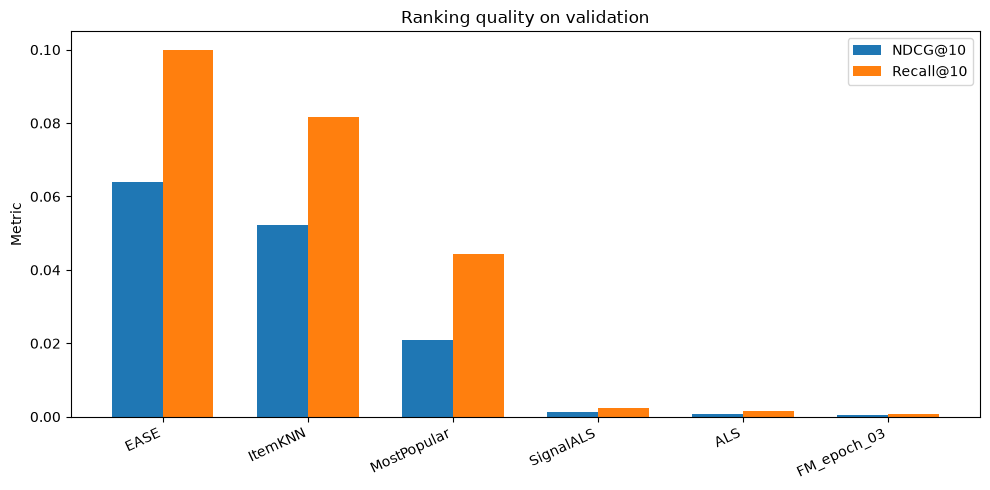

In [81]:
# Сравниваем качество ранжирования
models = model_results["model"].to_list()
x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width / 2, model_results["ndcg@10"], width, label="NDCG@10")
plt.bar(x + width / 2, model_results["recall@10"], width, label="Recall@10")
plt.xticks(x, models, rotation=25, ha="right")
plt.ylabel("Metric")
plt.title("Ranking quality on validation")
plt.legend()
plt.tight_layout()
plt.show()

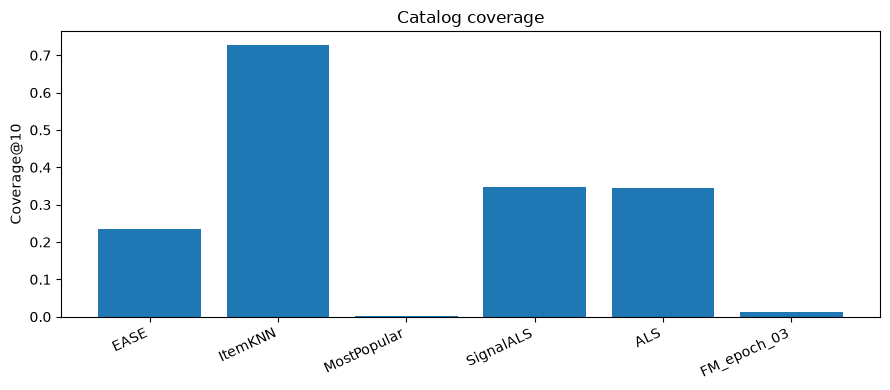

In [82]:
# Сравниваем покрытие каталога
plt.figure(figsize=(9, 4))
plt.bar(model_results["model"], model_results["coverage@10"])
plt.xticks(rotation=25, ha="right")
plt.ylabel("Coverage@10")
plt.title("Catalog coverage")
plt.tight_layout()
plt.show()

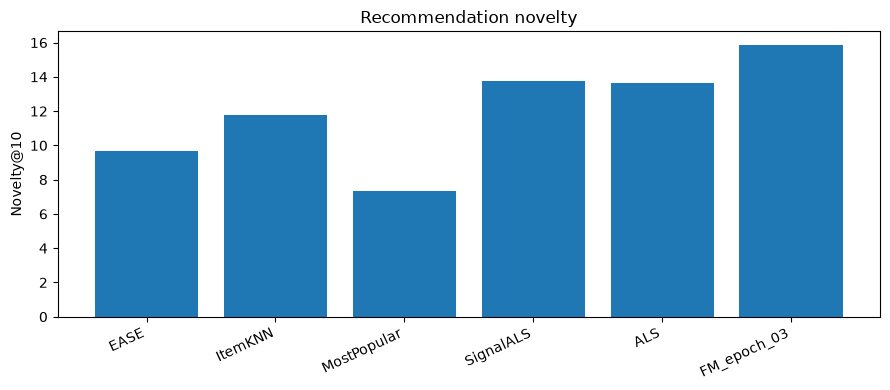

In [83]:
# Сравниваем novelty рекомендаций
plt.figure(figsize=(9, 4))
plt.bar(model_results["model"], model_results["novelty@10"])
plt.xticks(rotation=25, ha="right")
plt.ylabel("Novelty@10")
plt.title("Recommendation novelty")
plt.tight_layout()
plt.show()

In [84]:
# Смотрим, как validation-качество FM меняется по эпохам
fm_results = (
    results
    .filter(pl.col("model").str.starts_with("FM_"))
    .with_columns(pl.col("model").str.extract(r"(\d+)$").cast(pl.Int32).alias("epoch"))
    .sort("epoch")
)

fm_results.select("epoch", "ndcg@10", "recall@10", "coverage@10")

epoch,ndcg@10,recall@10,coverage@10
i32,f64,f64,f64
3,0.000438,0.000844,0.011693
6,0.000181,0.000376,0.011943
9,0.000105,0.000264,0.012568
12,0.000076,0.000193,0.01238
15,0.000081,0.000203,0.012505


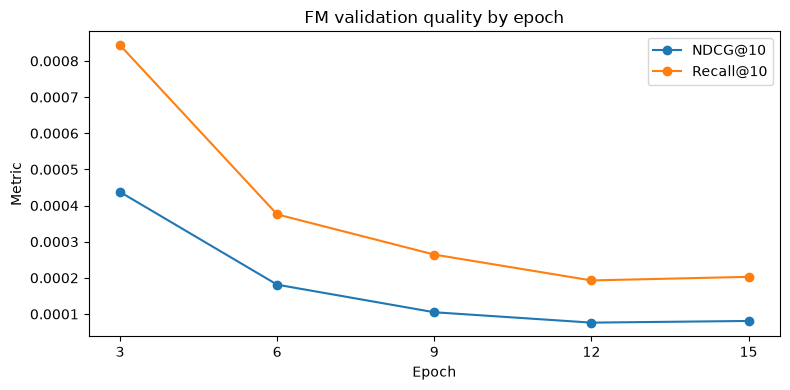

In [85]:
# Строим ranking-метрики FM по эпохам
plt.figure(figsize=(8, 4))
plt.plot(fm_results["epoch"], fm_results["ndcg@10"], marker="o", label="NDCG@10")
plt.plot(fm_results["epoch"], fm_results["recall@10"], marker="o", label="Recall@10")
plt.xlabel("Epoch")
plt.ylabel("Metric")
plt.title("FM validation quality by epoch")
plt.xticks(fm_results["epoch"])
plt.legend()
plt.tight_layout()
plt.show()

In [86]:
# Смотрим размер групп пользователей
per_user.select("user_id", "history_len", "history_group").unique().group_by("history_group").len().sort("history_group")

history_group,len
str,u32
"""1-2""",3869
"""11-20""",2556
"""21-50""",849
"""3-5""",8401
"""50+""",105
"""6-10""",5202


In [ ]:
per_user = per_user.with_columns(
    pl.when(pl.col("history_len") <= 2).then(pl.lit("1-2"))
    .when(pl.col("history_len") <= 5).then(pl.lit("3-5"))
    .when(pl.col("history_len") <= 10).then(pl.lit("6-10"))
    .when(pl.col("history_len") <= 20).then(pl.lit("11-20"))
    .when(pl.col("history_len") <= 50).then(pl.lit("21-50"))
    .otherwise(pl.lit("50+"))
    .alias("history_group")
)

In [88]:
# Средний NDCG@10 по группам активности
selected_models = model_results["model"].to_list()
groups = ["1-2", "3-5", "6-10", "11-20", "21-50", "50+"]

history_metrics = (
    per_user
    .filter(pl.col("model").is_in(selected_models))
    .group_by(["model", "history_group"])
    .agg(pl.col("ndcg@10").mean())
)

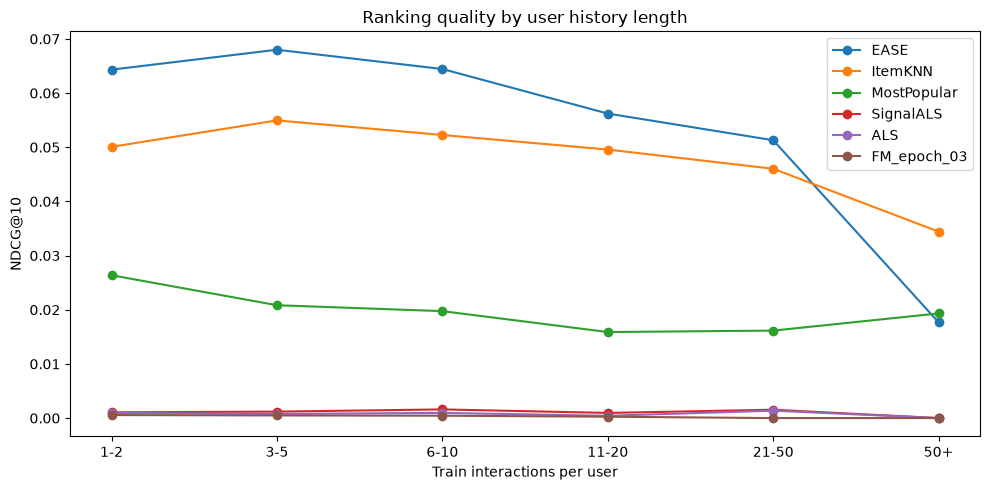

In [89]:
# Качество моделей для пользователей с разной длиной истории
plt.figure(figsize=(10, 5))

for model in selected_models:
    df = history_metrics.filter(pl.col("model") == model)
    values = {row["history_group"]: row["ndcg@10"] for row in df.iter_rows(named=True)}
    plt.plot(groups, [values.get(group, np.nan) for group in groups], marker="o", label=model)

plt.xlabel("Train interactions per user")
plt.ylabel("NDCG@10")
plt.title("Ranking quality by user history length")
plt.legend()
plt.tight_layout()
plt.show()

In [90]:
# Сравниваем базовый ALS и temporal SignalALS
als_comparison = model_results.filter(pl.col("model").is_in(["ALS", "SignalALS"]))
als_comparison.select("model", "ndcg@10", "recall@10", "coverage@10", "novelty@10")

model,ndcg@10,recall@10,coverage@10,novelty@10
str,f64,f64,f64,f64
"""SignalALS""",0.00125,0.002285,0.346339,13.742924
"""ALS""",0.00083,0.001642,0.344838,13.633739


In [94]:
# CI относится к исходным конфигурациям ALS/SignalALS (reg=0.1),
# сохранённым в validation_per_user.parquet, а не к результатам после tuning.
als_users = per_user.filter(pl.col("model") == "ALS").select(
    "user_id", pl.col("ndcg@10").alias("als")
)
signal_users = per_user.filter(pl.col("model") == "SignalALS").select(
    "user_id", pl.col("ndcg@10").alias("signal")
)
assert als_users["user_id"].n_unique() == als_users.height
assert signal_users["user_id"].n_unique() == signal_users.height
assert set(als_users["user_id"]) == set(signal_users["user_id"])

paired = als_users.join(signal_users, on="user_id")
delta = paired["signal"].to_numpy() - paired["als"].to_numpy()

rng = np.random.default_rng(42)
boot = np.array([
    rng.choice(delta, len(delta), replace=True).mean()
    for _ in range(5000)
])

print(f"ΔNDCG@10 = {delta.mean():.6f}")
print(
    f"95% CI = "
    f"[{np.quantile(boot, 0.025):.6f}, "
    f"{np.quantile(boot, 0.975):.6f}]"
)

ΔNDCG@10 = 0.000420
95% CI = [0.000210, 0.000648]


### Подбор гиперпараметров на validation

Гиперпараметры всех моделей выбираются только по validation. Основная метрика выбора — NDCG@10.

Для ItemKNN ранее подбиралось число соседей $k$, а для FM выбирается лучший checkpoint по validation NDCG@10.

Для остальных моделей рассматриваются следующие search spaces:

- ALS: $\lambda \in \{0.01, 0.1, 1.0\}$ при $d=32$;
- EASE: $\lambda \in \{100, 300, 500, 1000\}$;
- SignalALS: $\beta \in \{0.25, 0.5, 1.0\}$ и $\tau \in \{180, 365, 730\}$ дней при фиксированных параметрах базового ALS.

После выбора лучшей конфигурации test используется только один раз для финальной оценки.

In [95]:
import subprocess
import sys
import time
from pathlib import Path

from scripts.evaluate import prepare_data, recommend_als, recommend_ease, evaluate

train_eval, eval_users, targets_eval, seen_eval, history_len_eval, popularity_eval, candidate_items_eval = prepare_data()
total_interactions_eval = train_eval.height

print("Validation users:", len(eval_users))
print("Candidate items:", len(candidate_items_eval))

Validation users: 20982
Candidate items: 15993


In [101]:
def train_cpu_model(model, output, **kwargs):
    output = Path(output)

    required = {
        "als": ["users.npy", "items.npy", "user_factors.npy", "item_factors.npy"],
        "signal_als": ["users.npy", "items.npy", "user_factors.npy", "item_factors.npy"],
        "ease": ["users.npy", "items.npy", "B.npy"],
    }[model]

    if output.exists() and all((output / name).exists() for name in required):
        print("Use existing:", output)
        return output

    cmd = [sys.executable, "-m", "scripts.train_cpu_models", "--model", model, "--output", str(output)]

    for key, value in kwargs.items():
        cmd += ["--" + key.replace("_", "-"), str(value)]

    print("Training:", model, kwargs)
    subprocess.run(cmd, check=True)

    return output


def evaluate_als_path(name, path):
    recommendations = recommend_als(
        path,
        eval_users,
        seen_eval,
    )

    summary, _, _ = evaluate(
        name,
        recommendations,
        eval_users,
        targets_eval,
        history_len_eval,
        popularity_eval,
        candidate_items_eval,
        total_interactions_eval,
    )

    return summary


def evaluate_ease_path(name, path):
    recommendations = recommend_ease(
        train_eval,
        path,
        eval_users,
        seen_eval,
    )

    summary, _, _ = evaluate(
        name,
        recommendations,
        eval_users,
        targets_eval,
        history_len_eval,
        popularity_eval,
        candidate_items_eval,
        total_interactions_eval,
    )

    return summary

EASE tuning

In [102]:
ease_regs = [100, 300, 500, 1000]
ease_rows = []

for reg in ease_regs:
    path = Path("artifacts/ease/r300") if reg == 300 else Path(f"artifacts/ease/tuning_r{reg}")

    path = train_cpu_model(
        "ease",
        path,
        reg=reg,
        rating_threshold=4,
    )

    summary = evaluate_ease_path(f"EASE_r{reg}", path)

    ease_rows.append({
        "reg": reg,
        "ndcg@10": summary["ndcg@10"],
        "recall@10": summary["recall@10"],
    })

ease_tuning = pl.DataFrame(ease_rows).sort("ndcg@10", descending=True)
ease_tuning

Use existing: artifacts/ease/tuning_r100
EASE_r100: NDCG@10=0.06412 Recall@10=0.09982 Coverage@10=0.24755
Use existing: artifacts/ease/r300
EASE_r300: NDCG@10=0.06408 Recall@10=0.10000 Coverage@10=0.23354
Training: ease {'reg': 500, 'rating_threshold': 4}
model=ease
train_interactions=1021472
users=132463 items=15993 positive_interactions=759637 reg=500.0
stage=gram_matrix
stage=gram_matrix_done time=0.2s memory=0.95GB
stage=inverse
stage=inverse_done time=9.0s
saved_to=/home/ggotovskii/RecSys/hw1/artifacts/ease/tuning_r500
EASE_r500: NDCG@10=0.06407 Recall@10=0.10016 Coverage@10=0.22916
Training: ease {'reg': 1000, 'rating_threshold': 4}
model=ease
train_interactions=1021472
users=132463 items=15993 positive_interactions=759637 reg=1000.0
stage=gram_matrix
stage=gram_matrix_done time=0.2s memory=0.95GB
stage=inverse
stage=inverse_done time=9.1s
saved_to=/home/ggotovskii/RecSys/hw1/artifacts/ease/tuning_r1000
EASE_r1000: NDCG@10=0.06405 Recall@10=0.10003 Coverage@10=0.22416


reg,ndcg@10,recall@10
i64,f64,f64
100,0.064119,0.099821
300,0.064078,0.100001
500,0.064071,0.10016
1000,0.06405,0.100028


In [103]:
best_ease = ease_tuning.row(0, named=True)
best_ease

{'reg': 100, 'ndcg@10': 0.06411936574728354, 'recall@10': 0.09982131183233003}

ALS tuning

In [104]:
als_regs = [0.01, 0.1, 1.0]
als_rows = []

for reg in als_regs:
    if reg == 0.1:
        path = Path("artifacts/als/d32_r01")
    else:
        reg_tag = str(reg).replace(".", "")
        path = Path(f"artifacts/als/tuning_d32_r{reg_tag}")

    path = train_cpu_model(
        "als",
        path,
        factors=32,
        reg=reg,
        epochs=8,
        seed=42,
    )

    summary = evaluate_als_path(f"ALS_r{reg}", path)

    als_rows.append({
        "factors": 32,
        "reg": reg,
        "ndcg@10": summary["ndcg@10"],
        "recall@10": summary["recall@10"],
    })

als_tuning = pl.DataFrame(als_rows).sort("ndcg@10", descending=True)
als_tuning

Training: als {'factors': 32, 'reg': 0.01, 'epochs': 8, 'seed': 42}
model=als
train_interactions=1021472
users=132463 items=15993 interactions=1021472 factors=32 reg=0.01
epoch=1/8 time=6.5s
epoch=2/8 time=6.5s
epoch=3/8 time=6.5s
epoch=4/8 time=6.5s
epoch=5/8 time=6.5s
epoch=6/8 time=6.5s
epoch=7/8 time=6.5s
epoch=8/8 time=6.5s
saved_to=/home/ggotovskii/RecSys/hw1/artifacts/als/tuning_d32_r001
ALS_r0.01: NDCG@10=0.00033 Recall@10=0.00063 Coverage@10=0.10086
Use existing: artifacts/als/d32_r01
ALS_r0.1: NDCG@10=0.00083 Recall@10=0.00164 Coverage@10=0.34484
Training: als {'factors': 32, 'reg': 1.0, 'epochs': 8, 'seed': 42}
model=als
train_interactions=1021472
users=132463 items=15993 interactions=1021472 factors=32 reg=1.0
epoch=1/8 time=6.4s
epoch=2/8 time=6.4s
epoch=3/8 time=6.4s
epoch=4/8 time=6.4s
epoch=5/8 time=6.4s
epoch=6/8 time=6.4s
epoch=7/8 time=6.4s
epoch=8/8 time=7.1s
saved_to=/home/ggotovskii/RecSys/hw1/artifacts/als/tuning_d32_r10
ALS_r1.0: NDCG@10=0.01955 Recall@10=0.0343

factors,reg,ndcg@10,recall@10
i64,f64,f64,f64
32,1.0,0.01955,0.034356
32,0.1,0.00083,0.001642
32,0.01,0.000332,0.000628


In [105]:
best_als = als_tuning.row(0, named=True)
best_als

{'factors': 32,
 'reg': 1.0,
 'ndcg@10': 0.019550353376637967,
 'recall@10': 0.03435648039345278}

SignalALS tuning

In [106]:
best_als_reg = float(best_als["reg"])

signal_grid = [
    (0.25, 365),
    (0.5, 180),
    (0.5, 365),
    (0.5, 730),
    (1.0, 365),
]

signal_rows = []

for beta, tau_days in signal_grid:
    if best_als_reg == 0.1 and beta == 0.5 and tau_days == 365:
        path = Path("artifacts/signal_als/d32_r01_b05_t365")
    else:
        reg_tag = str(best_als_reg).replace(".", "")
        beta_tag = str(beta).replace(".", "")

        path = Path(
            f"artifacts/signal_als/"
            f"tuning_d32_r{reg_tag}_b{beta_tag}_t{tau_days}"
        )

    path = train_cpu_model(
        "signal_als",
        path,
        factors=32,
        reg=best_als_reg,
        epochs=8,
        beta=beta,
        tau_days=tau_days,
        seed=42,
    )

    summary = evaluate_als_path(
        f"SignalALS_b{beta}_t{tau_days}",
        path,
    )

    signal_rows.append({
        "factors": 32,
        "reg": best_als_reg,
        "beta": beta,
        "tau_days": tau_days,
        "ndcg@10": summary["ndcg@10"],
        "recall@10": summary["recall@10"],
    })

signal_tuning = pl.DataFrame(signal_rows).sort("ndcg@10", descending=True)
signal_tuning

Training: signal_als {'factors': 32, 'reg': 1.0, 'epochs': 8, 'beta': 0.25, 'tau_days': 365, 'seed': 42}
model=signal_als
train_interactions=1021472
signal=rating_recency beta=0.25 tau_days=365.0
users=132463 items=15993 interactions=1021472 factors=32 reg=1.0
epoch=1/8 time=6.7s
epoch=2/8 time=6.7s
epoch=3/8 time=6.7s
epoch=4/8 time=6.7s
epoch=5/8 time=6.7s
epoch=6/8 time=6.7s
epoch=7/8 time=6.7s
epoch=8/8 time=6.7s
saved_to=/home/ggotovskii/RecSys/hw1/artifacts/signal_als/tuning_d32_r10_b025_t365
SignalALS_b0.25_t365: NDCG@10=0.02054 Recall@10=0.03591 Coverage@10=0.06897
Training: signal_als {'factors': 32, 'reg': 1.0, 'epochs': 8, 'beta': 0.5, 'tau_days': 180, 'seed': 42}
model=signal_als
train_interactions=1021472
signal=rating_recency beta=0.5 tau_days=180.0
users=132463 items=15993 interactions=1021472 factors=32 reg=1.0
epoch=1/8 time=6.4s
epoch=2/8 time=6.5s
epoch=3/8 time=6.5s
epoch=4/8 time=6.5s
epoch=5/8 time=6.5s
epoch=6/8 time=6.4s
epoch=7/8 time=6.4s
epoch=8/8 time=6.4s
s

factors,reg,beta,tau_days,ndcg@10,recall@10
i64,f64,f64,i64,f64,f64
32,1.0,1.0,365,0.022933,0.040555
32,1.0,0.5,365,0.021176,0.036938
32,1.0,0.5,730,0.020868,0.036534
32,1.0,0.5,180,0.020652,0.036129
32,1.0,0.25,365,0.020538,0.035906


In [107]:
best_signal = signal_tuning.row(0, named=True)
best_signal

{'factors': 32,
 'reg': 1.0,
 'beta': 1.0,
 'tau_days': 365,
 'ndcg@10': 0.022932558716015374,
 'recall@10': 0.04055498253457041}

In [108]:
results = pl.read_csv("artifacts/evaluation/validation_metrics.csv")

best_fm = (
    results
    .filter(pl.col("model").str.starts_with("FM_"))
    .sort("ndcg@10", descending=True)
    .head(1)
)

best_configs = {
    "ItemKNN": {
        "n_neighbors": int(best_knn[0]),
    },
    "ALS": {
        "factors": 32,
        "reg": float(best_als["reg"]),
        "epochs": 8,
    },
    "SignalALS": {
        "factors": 32,
        "reg": float(best_signal["reg"]),
        "epochs": 8,
        "beta": float(best_signal["beta"]),
        "tau_days": int(best_signal["tau_days"]),
    },
    "EASE": {
        "reg": float(best_ease["reg"]),
        "rating_threshold": 4,
    },
    "FM": {
        "checkpoint": best_fm[0, "model"],
    },
}

best_configs

{'ItemKNN': {'n_neighbors': 400},
 'ALS': {'factors': 32, 'reg': 1.0, 'epochs': 8},
 'SignalALS': {'factors': 32,
  'reg': 1.0,
  'epochs': 8,
  'beta': 1.0,
  'tau_days': 365},
 'EASE': {'reg': 100.0, 'rating_threshold': 4},
 'FM': {'checkpoint': 'FM_epoch_03'}}

### Tuning results


In [ ]:
print("EASE")
display(ease_tuning)

print("ALS")
display(als_tuning)

print("SignalALS")
display(signal_tuning)

print("ItemKNN")
print("k =", best_knn[0], "Recall@10 =", best_knn[1], "NDCG@10 =", best_knn[2])

print("FM")
display(best_fm)

EASE


reg,ndcg@10,recall@10
i64,f64,f64
100,0.064119,0.099821
300,0.064078,0.100001
500,0.064071,0.10016
1000,0.06405,0.100028


ALS


factors,reg,ndcg@10,recall@10
i64,f64,f64,f64
32,1.0,0.01955,0.034356
32,0.1,0.00083,0.001642
32,0.01,0.000332,0.000628


SignalALS


factors,reg,beta,tau_days,ndcg@10,recall@10
i64,f64,f64,i64,f64,f64
32,1.0,1.0,365,0.022933,0.040555
32,1.0,0.5,365,0.021176,0.036938
32,1.0,0.5,730,0.020868,0.036534
32,1.0,0.5,180,0.020652,0.036129
32,1.0,0.25,365,0.020538,0.035906


ItemKNN
k = 400 Recall@10 = 0.08421501253774709 NDCG@10 = 0.05327474772041353
FM


model,ndcg@10,recall@10,precision@10,hit_rate@10,mrr@10,coverage@10,novelty@10,avg_popularity@10
str,f64,f64,f64,f64,f64,f64,f64,f64
"""FM_epoch_03""",0.000438,0.000844,0.000114,0.001096,0.000398,0.011693,15.86475,26.207082


### 6. Анализ результатов на validation

#### 1. Сравнение качества ранжирования (Accuracy vs Coverage)
По результатам валидации наилучшую точность ранжирования продемонстрировал **EASE**: $\mathrm{NDCG@10} = 0.0641$, $\mathrm{Recall@10} = 0.1000$. Второе место занял **ItemKNN** с $\mathrm{NDCG@10} = 0.0523$ и $\mathrm{Recall@10} = 0.0817$. EASE превосходит ItemKNN по целевой метрике примерно на 22.6%, однако этот прирост сопряжен с существенным сужением пространства рекомендаций:
- **EASE:** $\mathrm{Coverage@10} = 0.234$;
- **ItemKNN:** $\mathrm{Coverage@10} = 0.728$.

Таким образом, ItemKNN обеспечивает существенно более широкое покрытие каталога, задействуя длинный хвост каталога, тогда как EASE сильнее концентрируется на плотном ядре совместимых объектов. Неперсонализированный бейзлайн **MostPopular** предсказуемо уступает обоим методам по точности ранжирования и практически не исследует каталог ($\mathrm{Coverage@10} \approx 0.0014$), что подтверждает необходимость персонализации.

#### 2. Проблема несоответствия оптимизационного функционала (Objective Mismatch)
Модели матричной факторизации с явной обратной связью показали низкие абсолютные значения Top-10 метрик:
- **Explicit ALS:** $\mathrm{NDCG@10} = 0.00083$;
- **Factorization Machine (FM):** максимальный $\mathrm{NDCG@10} = 0.00044$ (достигнут на 3-й эпохе).

Этот результат объясняется несоответствием между задачей обучения и итоговой задачей ранжирования (objective mismatch).

Во время обучения ALS и FM минимизируют ошибку предсказания рейтингов только на наблюдаемых взаимодействиях $\mathcal{D}_{\text{train}}$.

Во время оценки модель должна ранжировать около $16,000$ candidate items, большинство из которых отсутствовали среди наблюдаемых user-item пар в train.

Поэтому хорошее предсказание известных рейтингов не гарантирует правильного порядка объектов при full-catalog Top-10 ranking.
### 6. Анализ результатов на validation

#### 1. Сравнение качества ранжирования

После подбора гиперпараметров лучший результат на validation показал **EASE** с $\lambda=100$:

- $\mathrm{NDCG@10}=0.06412$;
- $\mathrm{Recall@10}=0.09982$.

Второе место занимает **ItemKNN** с $k=400$:

- $\mathrm{NDCG@10}=0.05327$;
- $\mathrm{Recall@10}=0.08422$.

Таким образом, EASE превосходит ItemKNN по основной метрике NDCG@10 примерно на $20.4\%$.

При этом EASE оказался практически нечувствителен к регуляризации в исследованном диапазоне: при $\lambda \in \{100,300,500,1000\}$ значение NDCG@10 меняется только от $0.06405$ до $0.06412$.

---

#### 2. Результаты Explicit ALS

Для ALS регуляризация оказалась существенно важнее. При фиксированной размерности факторов $d=32$ получены следующие результаты:

- $\lambda=0.01$: $\mathrm{NDCG@10}=0.00033$;
- $\lambda=0.1$: $\mathrm{NDCG@10}=0.00083$;
- $\lambda=1.0$: $\mathrm{NDCG@10}=0.01955$.

Таким образом, лучшая конфигурация — $d=32$, $\lambda=1.0$, для которой:

$$
\mathrm{NDCG@10}=0.01955,
\qquad
\mathrm{Recall@10}=0.03436.
$$

Это показывает, что низкий результат исходной ALS-конфигурации был связан не только с особенностями explicit-feedback постановки, но и с недостаточной регуляризацией.

---

#### 3. Эффект Custom-Signal ALS

Для SignalALS параметры базовой ALS были зафиксированы на лучшей конфигурации $d=32$, $\lambda=1.0$, после чего подбирались параметры временного сигнала $\beta$ и $\tau$.

Лучший результат получен при:

$$
\beta=1.0,
\qquad
\tau=365 \text{ дней}.
$$

Для этой конфигурации:

$$
\mathrm{NDCG@10}=0.02293,
\qquad
\mathrm{Recall@10}=0.04056.
$$

По сравнению с лучшим baseline ALS:

$$
0.01955 \rightarrow 0.02293,
$$

что соответствует приросту NDCG@10 примерно на $17.3\%$. Recall@10 также увеличился примерно на $18\%$.

Таким образом, добавление временной информации в target даёт положительный эффект даже после отдельного подбора регуляризации базового ALS.

---

#### 4. Factorization Machine

Лучший результат FM получен на 3-й эпохе:

$$
\mathrm{NDCG@10}=0.00044,
\qquad
\mathrm{Recall@10}=0.00084.
$$

После 3-й эпохи обучающая ошибка MSE продолжала уменьшаться, однако ranking-метрики на validation ухудшались.

В данном случае хорошо видна проблема несоответствия задачи обучения и итоговой задачи ранжирования: FM обучается предсказывать рейтинги на наблюдаемых user-item парах, тогда как на validation должна выбрать Top-10 среди примерно $16\,000$ кандидатов.

Поэтому уменьшение ошибки предсказания рейтингов не гарантирует улучшения full-catalog Top-10 ranking.

---

#### 5. Итог

После tuning модели располагаются по NDCG@10 следующим образом:

$$
\mathrm{EASE}\;(0.06412)
>
\mathrm{ItemKNN}\;(0.05327)
>
\mathrm{SignalALS}\;(0.02293)
>
\mathrm{ALS}\;(0.01955)
\gg
\mathrm{FM}\;(0.00044).
$$

EASE остаётся лучшей моделью по качеству ранжирования, а ItemKNN занимает второе место. Для ALS подбор регуляризации существенно улучшил результат, а использование временного target в SignalALS дало дополнительный прирост относительно лучшей конфигурации обычного ALS.

FM, напротив, остаётся слабой именно в задаче full-catalog Top-10 ranking, несмотря на уменьшение обучающего MSE.
Для **FM** этот эффект проявился наиболее наглядно: после 3-й эпохи обучающая ошибка $\mathrm{MSE}_{\text{train}}$ продолжала монотонно убывать, тогда как метрики ранжирования $\mathrm{NDCG@10}$ и $\mathrm{Recall@10}$ на валидации начали деградировать. Это прямо демонстрирует, что оптимизация точности предсказания точечных рейтингов не эквивалентна задаче персонального Top-$K$ ранжирования.

#### 3. Эффект модифицированного целевого сигнала (SignalALS)
Введение временного затухания в целевую переменную повысило метрику $\mathrm{NDCG@10}$ с $0.00083$ до $0.00125$ (относительный прирост $+50.6\%$).

Проверка устойчивости с помощью парного bootstrap-анализа по пользователям валидационной когорты показала:
$$\Delta\mathrm{NDCG@10} = 0.000420, \qquad 95\%\text{ CI} = [0.000210, \; 0.000648]$$

Поскольку доверительный интервал строго положителен и не накрывает ноль, эффект temporal-сигнала является статистически значимым. Тем не менее, абсолютный уровень качества SignalALS остается ограниченным той же архитектурной проблемой explicit-постановки.

#### 4. Анализ Novelty и длина профиля пользователя
- **Novelty:** Высокие показатели новизны у ALS, SignalALS и FM являются артефактом разброса нескорректированных скоров по ненаблюдаемым объектам каталога, а не признаком качественной исследовательской выдачи. Напротив, EASE и ItemKNN находят баланс между релевантностью и популярностью.
- **Длина пользовательской истории:** EASE и ItemKNN наиболее эффективны на когортах с малым и средним числом обучающих действий. В сегменте сверхактивных пользователей ($50+$ интеракций) ItemKNN незначительно опережает EASE, однако малый объем когорты ($N \approx 100$) обуславливает высокую дисперсию и требует осторожной трактовки.

Заключение

Проблема в том, что ALS и FM учатся предсказывать рейтинги только для тех user-item пар, которые уже были в train.

На validation задача другая: для каждого пользователя нужно выбрать Top-10 примерно из $16,000$ кандидатов, большинство из которых не встречались с этим пользователем в train.

Поэтому низкая ошибка на известных рейтингах ещё не означает, что модель хорошо ранжирует весь каталог.

### 7. Финальная оценка на test

После подбора гиперпараметров на validation выбирается одна конфигурация каждой модели. Test не используется ни для обучения, ни для выбора параметров и применяется только для финального сравнения.

Критерий релевантности остаётся неизменным:

$$
r_{ui} \ge 4.
$$

В evaluation включаются только пользователи и объекты, присутствующие в train. Для каждого пользователя из кандидатов исключаются все объекты из его train-истории:

$$
C_u = I_{\text{train}} \setminus I_u^{\text{train}}.
$$

Основные финальные метрики — NDCG@10 и Recall@10.

In [110]:
test = pl.read_parquet("data/processed/test.parquet")

train_users = train.select("user_id").unique()
train_items = train.select("item_id").unique()

# Оставляем только warm users/items
test_warm = (
    test
    .join(train_users, on="user_id", how="semi")
    .join(train_items, on="item_id", how="semi")
)

# Релевантные test-items
test_relevant = test_warm.filter(pl.col("rating") >= 4)

# Оцениваем только пользователей, у которых есть хотя бы один relevant item
test_targets_df = (
    test_relevant
    .group_by("user_id")
    .agg(pl.col("item_id").alias("relevant_items"))
)

test_users = test_targets_df["user_id"].to_list()

test_targets = {
    row["user_id"]: set(row["relevant_items"])
    for row in test_targets_df.iter_rows(named=True)
}

# Train-history остаётся той же, что использовалась моделями
test_seen = {
    row["user_id"]: set(row["seen_items"])
    for row in train_history.iter_rows(named=True)
}

print("Test interactions:", test.height)
print("Warm test interactions:", test_warm.height)
print("Relevant test interactions:", test_relevant.height)
print("Evaluation users:", len(test_users))
print("Candidate items:", train_items.height)

Test interactions: 127684
Warm test interactions: 35249
Relevant test interactions: 25185
Evaluation users: 13460
Candidate items: 15993


In [114]:
# Лучшие конфигурации

best_configs = {
    "ItemKNN": {
        "n_neighbors": 400,
    },

    "ALS": {
        "factors": 32,
        "reg": 1.0,
        "epochs": 8,
        "artifact": "artifacts/als/tuning_d32_r10",
    },

    "SignalALS": {
        "factors": 32,
        "reg": 1.0,
        "epochs": 8,
        "beta": 1.0,
        "tau_days": 365,
        "artifact": "artifacts/signal_als/tuning_d32_r10_b10_t365",
    },

    "EASE": {
        "reg": 100,
        "artifact": "artifacts/ease/tuning_r100",
    },

    "FM": {
        "checkpoint": "artifacts/fm/clean_d32/checkpoint_epoch_03.pt",
    },
}

best_configs

{'ItemKNN': {'n_neighbors': 400},
 'ALS': {'factors': 32,
  'reg': 1.0,
  'epochs': 8,
  'artifact': 'artifacts/als/tuning_d32_r10'},
 'SignalALS': {'factors': 32,
  'reg': 1.0,
  'epochs': 8,
  'beta': 1.0,
  'tau_days': 365,
  'artifact': 'artifacts/signal_als/tuning_d32_r10_b10_t365'},
 'EASE': {'reg': 100, 'artifact': 'artifacts/ease/tuning_r100'},
 'FM': {'checkpoint': 'artifacts/fm/clean_d32/checkpoint_epoch_03.pt'}}

In [115]:
for name in ["ALS", "SignalALS", "EASE"]:
    path = Path(best_configs[name]["artifact"])
    assert path.is_dir(), f"Missing artifact: {path}"
    print(name, path)

fm_checkpoint = Path(best_configs["FM"]["checkpoint"])
assert fm_checkpoint.is_file(), f"Missing checkpoint: {fm_checkpoint}"

print("FM:", fm_checkpoint)

ALS artifacts/als/tuning_d32_r10
SignalALS artifacts/signal_als/tuning_d32_r10_b10_t365
EASE artifacts/ease/tuning_r100
FM: artifacts/fm/clean_d32/checkpoint_epoch_03.pt


In [117]:
from scripts.evaluate import (
    evaluate,
    recommend_most_popular,
    recommend_als,
    recommend_ease,
    recommend_fm,
)
from models.item_knn import ItemKNN

In [118]:
# Диагностические признаки берём только из train, как при validation.
# Здесь test означает назначение словарей, а не источник статистик.
test_history_len = {
    row["user_id"]: row["history_len"]
    for row in train.group_by("user_id").agg(pl.len().alias("history_len")).iter_rows(named=True)
}
test_popularity = {
    row["item_id"]: row["popularity"]
    for row in train.group_by("item_id").agg(pl.len().alias("popularity")).iter_rows(named=True)
}

test_summaries = []
test_per_user = []
test_recommendations = []

def add_test_result(name, recommendations):
    assert all(user_id in recommendations for user_id in test_users)
    assert all(not (set(recommendations[u]) & test_seen[u]) for u in test_users)

    summary, metrics_df, recommendations_df = evaluate(
        name,
        recommendations,
        test_users,
        test_targets,
        test_history_len,
        test_popularity,
        candidate_items,
        train.height,
    )

    test_summaries.append(summary)
    test_per_user.append(metrics_df)
    test_recommendations.append(recommendations_df)


# MostPopular
add_test_result("MostPopular", recommend_most_popular(train, test_users, test_seen))

# ItemKNN
knn = ItemKNN(n_neighbors=best_configs["ItemKNN"]["n_neighbors"], rating_threshold=4).fit(train)
add_test_result("ItemKNN", {u: knn.recommend(u, k=10) for u in test_users})

# ALS
add_test_result("ALS", recommend_als(
    Path(best_configs["ALS"]["artifact"]), test_users, test_seen
))

# SignalALS
add_test_result("SignalALS", recommend_als(
    Path(best_configs["SignalALS"]["artifact"]), test_users, test_seen
))

# EASE
add_test_result("EASE", recommend_ease(
    train, Path(best_configs["EASE"]["artifact"]), test_users, test_seen
))

# FM
add_test_result("FM", recommend_fm(
    Path(best_configs["FM"]["checkpoint"]), test_users, test_seen
))

MostPopular: NDCG@10=0.02034 Recall@10=0.04137 Coverage@10=0.00138
ItemKNN: NDCG@10=0.03891 Recall@10=0.06594 Coverage@10=0.64516
ALS: NDCG@10=0.01745 Recall@10=0.03151 Coverage@10=0.06053
SignalALS: NDCG@10=0.01879 Recall@10=0.03380 Coverage@10=0.05790
EASE: NDCG@10=0.04882 Recall@10=0.08164 Coverage@10=0.21522
FM: NDCG@10=0.00066 Recall@10=0.00107 Coverage@10=0.01144


In [120]:
#сдампим
output = Path("artifacts/evaluation")
output.mkdir(parents=True, exist_ok=True)

test_results = pl.DataFrame(test_summaries).sort("ndcg@10", descending=True)

test_results.write_csv(output / "test_metrics.csv")
pl.concat(test_per_user).write_parquet(output / "test_per_user.parquet")
pl.concat(test_recommendations).write_parquet(output / "test_recommendations.parquet")

test_results

model,ndcg@10,recall@10,precision@10,hit_rate@10,mrr@10,coverage@10,novelty@10,avg_popularity@10
str,f64,f64,f64,f64,f64,f64,f64,f64
"""EASE""",0.048825,0.081639,0.014086,0.12578,0.050341,0.215219,9.819605,2451.95234
"""ItemKNN""",0.038905,0.065944,0.011538,0.101709,0.039694,0.645157,11.622702,1657.949079
"""MostPopular""",0.020338,0.041368,0.007615,0.071991,0.018941,0.001376,7.366345,6430.671441
"""SignalALS""",0.018787,0.033799,0.006204,0.059064,0.019261,0.0579,8.970933,2791.537088
"""ALS""",0.017449,0.031511,0.005661,0.054309,0.017836,0.060526,8.78235,3077.984799
"""FM""",0.000662,0.001071,0.000156,0.001486,0.000654,0.011443,15.86567,26.233871


In [121]:
test_results = pl.DataFrame(test_summaries).sort("ndcg@10", descending=True)

validation_best = pl.DataFrame([
    {"model": "MostPopular", "ndcg_val": float(results.filter(pl.col("model") == "MostPopular")["ndcg@10"][0]), "recall_val": float(results.filter(pl.col("model") == "MostPopular")["recall@10"][0])},
    {"model": "ItemKNN", "ndcg_val": float(best_knn[2]), "recall_val": float(best_knn[1])},
    {"model": "ALS", "ndcg_val": float(best_als["ndcg@10"]), "recall_val": float(best_als["recall@10"])},
    {"model": "SignalALS", "ndcg_val": float(best_signal["ndcg@10"]), "recall_val": float(best_signal["recall@10"])},
    {"model": "EASE", "ndcg_val": float(best_ease["ndcg@10"]), "recall_val": float(best_ease["recall@10"])},
    {"model": "FM", "ndcg_val": float(best_fm[0, "ndcg@10"]), "recall_val": float(best_fm[0, "recall@10"])},
])

comparison = (
    validation_best
    .join(
        test_results.select("model", "ndcg@10", "recall@10", "coverage@10"),
        on="model",
    )
    .rename({"ndcg@10": "ndcg_test", "recall@10": "recall_test"})
    .sort("ndcg_val", descending=True)
)

comparison

model,ndcg_val,recall_val,ndcg_test,recall_test,coverage@10
str,f64,f64,f64,f64,f64
"""EASE""",0.064119,0.099821,0.048825,0.081639,0.215219
"""ItemKNN""",0.053275,0.084215,0.038905,0.065944,0.645157
"""SignalALS""",0.022933,0.040555,0.018787,0.033799,0.0579
"""MostPopular""",0.020785,0.044369,0.020338,0.041368,0.001376
"""ALS""",0.01955,0.034356,0.017449,0.031511,0.060526
"""FM""",0.000438,0.000844,0.000662,0.001071,0.011443


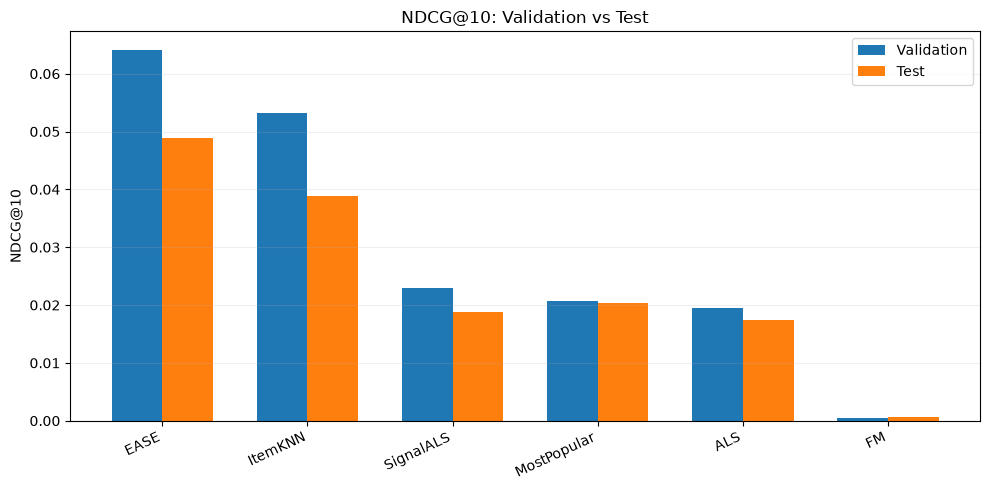

In [122]:
models = comparison["model"].to_list()
x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(x - width / 2, comparison["ndcg_val"].to_numpy(), width, label="Validation")
ax.bar(x + width / 2, comparison["ndcg_test"].to_numpy(), width, label="Test")

ax.set_xticks(x, models, rotation=25, ha="right")
ax.set_ylabel("NDCG@10")
ax.set_title("NDCG@10: Validation vs Test")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

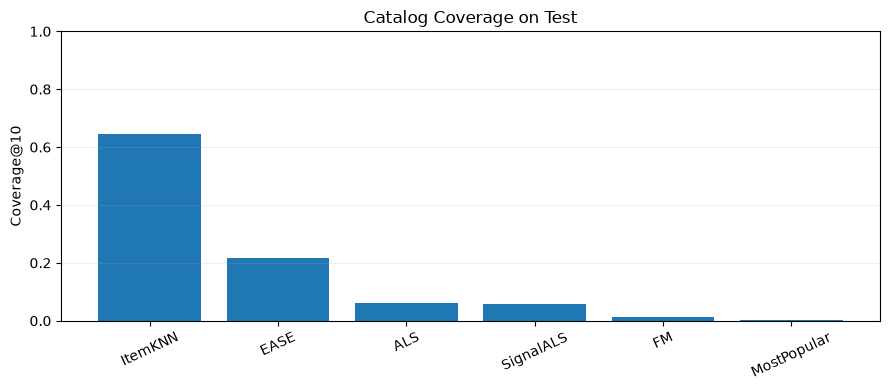

In [123]:
coverage = test_results.sort("coverage@10", descending=True)

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(coverage["model"].to_list(), coverage["coverage@10"].to_numpy())

ax.set_ylim(0, 1)
ax.set_ylabel("Coverage@10")
ax.set_title("Catalog Coverage on Test")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

### 8. Итоговые выводы

#### 1. Качество рекомендаций

Лучшей моделью на test стала **EASE** с NDCG@10 = 0.04882 и Recall@10 = 0.08164. Второе место заняла **ItemKNN** с NDCG@10 = 0.03891 и Recall@10 = 0.06594. Таким образом, EASE превосходит ItemKNN по основной метрике примерно на 25.5%.

При этом ItemKNN обеспечивает значительно более широкое покрытие каталога: Coverage@10 = 0.645 против 0.215 у EASE. Получается, что EASE лучше ранжирует релевантные объекты, а ItemKNN использует почти в три раза большую часть каталога.

#### 2. Сравнение validation и test

На test качество большинства моделей снизилось. У EASE NDCG@10 уменьшился с 0.06412 до 0.04882 (−23.9%), у ItemKNN — с 0.05327 до 0.03891 (−27.0%).

Возможная причина — изменение пользовательских предпочтений и распределения взаимодействий со временем. При этом evaluation проводится на разных временных периодах и пользовательских когортах, поэтому снижение метрик нельзя однозначно объяснить только временным сдвигом.

#### 3. Эффект Custom-Signal ALS

После подбора регуляризации качество ALS значительно улучшилось: при reg = 1.0 модель достигла NDCG@10 = 0.01955 на validation.

Использование временного target дало дополнительный прирост. На validation SignalALS превосходит обычный ALS по NDCG@10 на 17.3%, а на test — на 7.7% (0.01879 против 0.01745).

Таким образом, временной сигнал улучшил результаты в обоих периодах, хотя его эффект на test оказался слабее. При этом обе модели уступили даже неперсонализированному MostPopular, поэтому их абсолютное качество остаётся ограниченным.

#### 4. Результаты FM

FM показала самое низкое качество ранжирования: NDCG@10 = 0.00066 на test.

В ходе обучения MSE уменьшалась, однако качество Top-10 рекомендаций на validation ухудшалось. Возможное объяснение — *objective mismatch*: модель учится предсказывать рейтинги наблюдаемых user-item пар, но при оценке должна ранжировать почти 16 000 кандидатов.

Следовательно, хорошее предсказание рейтингов само по себе не гарантирует хорошего full-catalog ranking.

#### 5. Ограничения и заключение

Оценка проводилась только для warm users и warm items, поэтому результаты не отражают качество моделей при cold-start. Кроме того, iterative 5-core фильтрация была выполнена до временного разбиения, что создаёт некоторое смещение при формировании выборки.

**В итоге EASE показала лучшее качество Top-10 рекомендаций, ItemKNN — самое широкое покрытие каталога, а Custom-Signal ALS продемонстрировала положительный эффект от использования временной информации.** При этом полученные результаты показывают, насколько важны подбор регуляризации и соответствие обучающей задачи итоговой метрике ранжирования.